# College Football Upset Vulnerability — Stage 4: First Classification Benchmarks


## 0. Mount Google Drive and load the manifests



In [ ]:
from google.colab import drive
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, brier_score_loss, log_loss, roc_auc_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/CFB_Upset_Project')
PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'validation'

paths = {
    'matchups': PROCESSED_DIR / 'matchup_features_initial.csv',
    'eligibility': PROCESSED_DIR / 'game_eligibility_and_splits.csv',
    'features': PROCESSED_DIR / 'initial_feature_columns.json',
    'split_manifest': PROCESSED_DIR / 'split_manifest.json',
}
for name, path in paths.items():
    if not path.is_file():
        raise FileNotFoundError(f'Missing {name}: {path}. Finish the previous stage first.')

matchups = pd.read_csv(paths['matchups'], parse_dates=['date'], low_memory=False)
eligibility = pd.read_csv(paths['eligibility'], low_memory=False)
feature_manifest = json.loads(paths['features'].read_text(encoding='utf-8'))
split_manifest = json.loads(paths['split_manifest'].read_text(encoding='utf-8'))

print('Matchup rows:', f'{len(matchups):,}')
print('Eligibility rows:', f'{len(eligibility):,}')
print('Python / pandas / sklearn:', __import__('sys').version.split()[0],
      pd.__version__, sklearn.__version__)
print('Candidate feature names from Stage 2:', len(feature_manifest['feature_columns']))
print('Validation folds:', [f['fold'] for f in split_manifest['validation_folds']])
print('Reserved final test seasons:', split_manifest['test_seasons'])

Mounted at /content/drive
Matchup rows: 18,300
Eligibility rows: 18,300
Python / pandas / sklearn: 3.13.18 2.2.3 1.6.1
Candidate feature names from Stage 2: 19
Validation folds: ['val_2019', 'val_2020', 'val_2021', 'val_2022', 'val_2023']
Reserved final test seasons: [2024, 2025]


## 1. Join eligibility and protect the final test period


In [ ]:
join_keys = ['game_id', 'season', 'home', 'away']
assert matchups['game_id'].is_unique and eligibility['game_id'].is_unique

required_eligibility_cols = join_keys + ['game_category', 'primary_fbs_fbs', 'partition']
missing_join_cols = set(required_eligibility_cols) - set(eligibility.columns)
if missing_join_cols:
    raise KeyError(f'Eligibility file lacks: {sorted(missing_join_cols)}')

joined = matchups.merge(
    eligibility[required_eligibility_cols],
    on=join_keys, how='left', validate='one_to_one', indicator=True
)
assert joined['_merge'].eq('both').all(), 'Some matchups lacked an eligibility match'
joined = joined.drop(columns=['_merge'])

# Robust parsing if a CSV reader interprets true/false as strings.
def parse_bool(series):
    converted = series.astype(str).str.strip().str.lower().map(
        {'true': True, 'false': False, '1': True, '0': False}
    )
    if converted.isna().any():
        raise ValueError(f'Unexpected Boolean values in {series.name}')
    return converted.astype(bool)

joined['primary_fbs_fbs'] = parse_bool(joined['primary_fbs_fbs'])
joined['neutral'] = parse_bool(joined['neutral'])

TEST_SEASONS = set(map(int, split_manifest['test_seasons']))
assert TEST_SEASONS == {2024, 2025}, 'Expected reserved test seasons to be 2024–2025'
folds = split_manifest['validation_folds']
assert [int(f['validation_season']) for f in folds] == [2019, 2020, 2021, 2022, 2023]
assert max(int(f['validation_season']) for f in folds) < min(TEST_SEASONS)

# Make the modeling dataframe incapable of containing a test-season observation.
modeling = joined.loc[
    joined['primary_fbs_fbs'] & ~joined['season'].isin(TEST_SEASONS)
].copy()
assert set(modeling['season']).issubset(set(range(2004, 2024)))
assert modeling['game_id'].is_unique
assert modeling['home_win'].isin([0, 1]).all()
assert modeling['partition'].isin(['initial_training', 'validation_era']).all()

print('Eligible FBS–FBS games through 2023:', f'{len(modeling):,}')
print('Validation-era FBS–FBS games:',
      f"{modeling['season'].between(2019, 2023).sum():,}")
print('Reserved 2024–2025 observations in modeling table:',
      modeling['season'].isin(TEST_SEASONS).sum())
display(modeling.groupby('season').size().rename('eligible_games').to_frame().tail(8))

Eligible FBS–FBS games through 2023: 14,563
Validation-era FBS–FBS games: 3,646
Reserved 2024–2025 observations in modeling table: 0


,eligible_games
season,
2016,760
2017,776
2018,772
2019,774
2020,534
2021,770
2022,776
2023,792


## 2. Choose controlled feature groups (no test data)



In [ ]:
ALL_INITIAL = list(feature_manifest['feature_columns'])
assert len(ALL_INITIAL) == 19 and len(ALL_INITIAL) == len(set(ALL_INITIAL))

RECORD_FEATURES = [
    'neutral',
    'home_season_prior_games', 'away_season_prior_games',
    'home_season_prior_win_pct', 'away_season_prior_win_pct',
    'diff_season_prior_win_pct',
]
FEATURE_SETS = {
    'venue_only': ['neutral'],
    'record_and_venue': RECORD_FEATURES,
    'initial_19': ALL_INITIAL,
}

banned_exact = {
    'home_win', 'home_margin', 'score_home', 'score_away',
    'game_id', 'date', 'season', 'home', 'away', 'week',
}
for name, features in FEATURE_SETS.items():
    assert features, name
    assert set(features).issubset(ALL_INITIAL), f'{name} contains unapproved features'
    assert set(features).isdisjoint(banned_exact), f'{name} includes leakage features'
    missing = set(features) - set(modeling.columns)
    if missing:
        raise KeyError(f'Features missing for {name}: {sorted(missing)}')

# Convert input features once; the imputation and scaling themselves are fold-specific.
for feature in ALL_INITIAL:
    if feature == 'neutral':
        modeling[feature] = modeling[feature].astype(int)
    else:
        before_missing = modeling[feature].isna().sum()
        numeric = pd.to_numeric(modeling[feature], errors='coerce')
        if numeric.isna().sum() > before_missing:
            raise ValueError(f'Unexpected non-numeric values in {feature}')
        modeling[feature] = numeric.astype(float)

print('Feature groups:')
for name, features in FEATURE_SETS.items():
    print(f' - {name}: {len(features)} features')
print('Missing first-game averages are left as NaN and imputed inside each training fold.')
display(modeling[ALL_INITIAL].isna().mean().mul(100).round(1)
        .sort_values(ascending=False).rename('missing_percent').head(12).to_frame())

Feature groups:
 - venue_only: 1 features
 - record_and_venue: 6 features
 - initial_19: 19 features
Missing first-game averages are left as NaN and imputed inside each training fold.


,missing_percent
diff_season_prior_avg_total_yards,6.7
diff_season_prior_avg_margin,6.6
diff_days_since_previous_season_game,6.6
diff_season_prior_win_pct,6.6
away_season_prior_avg_total_yards,6.3
away_days_since_previous_season_game,6.2
away_season_prior_avg_margin,6.2
home_days_since_previous_season_game,6.2
home_season_prior_win_pct,6.2
home_season_prior_avg_total_yards,6.2


## 3. Define the model and comparison metrics


In [ ]:
def logistic_pipeline():
    return Pipeline([
        ('imputer', SimpleImputer(
            strategy='median', add_indicator=True, keep_empty_features=True
        )),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            solver='lbfgs', C=1.0, max_iter=2000, random_state=42
        )),
    ])


def evaluate_probability_predictions(y_true, probabilities):
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    assert len(y_true) == len(probabilities)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    predicted = (probabilities >= 0.5).astype(int)
    return {
        'n_games': len(y_true),
        'accuracy': accuracy_score(y_true, predicted),
        'brier': brier_score_loss(y_true, probabilities),
        'log_loss': log_loss(y_true, probabilities, labels=[0, 1]),
        'roc_auc': roc_auc_score(y_true, probabilities)
                   if len(np.unique(y_true)) == 2 else np.nan,
    }

print('Logistic Regression pipeline:', logistic_pipeline())

Logistic Regression pipeline: Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, keep_empty_features=True,
                               strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])


## 4. Run five expanding-window validation folds



In [ ]:
rows = []
validation_predictions = []

for fold in folds:
    fold_name = str(fold['fold'])
    first_year, last_year = map(int, fold['train_seasons'])
    val_year = int(fold['validation_season'])
    assert first_year == 2004 and last_year == val_year - 1

    train = modeling.loc[modeling['season'].between(first_year, last_year)].copy()
    val = modeling.loc[modeling['season'].eq(val_year)].copy()
    assert len(train) > 0 and len(val) > 0
    assert train['season'].max() < val['season'].min()
    assert set(train['game_id']).isdisjoint(set(val['game_id']))

    y_train = train['home_win'].astype(int).to_numpy()
    y_val = val['home_win'].astype(int).to_numpy()

    # Constant-probability baseline learned from TRAIN only.
    historical_home_rate = float(y_train.mean())
    constant_probabilities = np.full(len(val), historical_home_rate)
    base_metrics = evaluate_probability_predictions(y_val, constant_probabilities)
    rows.append({'fold': fold_name, 'validation_season': val_year,
                 'model': 'constant_train_home_rate',
                 'n_train': len(train), **base_metrics,
                 'always_home_accuracy': float(y_val.mean())})

    val_info = val[['game_id', 'season', 'date', 'away', 'home']].copy()
    for model_name, feature_names in FEATURE_SETS.items():
        model = logistic_pipeline()
        model.fit(train[feature_names], y_train)
        classes = model.named_steps['classifier'].classes_
        prob_home = model.predict_proba(val[feature_names])[:, list(classes).index(1)]
        metrics = evaluate_probability_predictions(y_val, prob_home)
        rows.append({'fold': fold_name, 'validation_season': val_year,
                     'model': model_name, 'n_train': len(train), **metrics,
                     'always_home_accuracy': float(y_val.mean())})

        one_fold = val_info.copy()
        one_fold['fold'] = fold_name
        one_fold['model'] = model_name
        one_fold['actual_home_win'] = y_val
        one_fold['predicted_p_home_win'] = prob_home
        one_fold['predicted_home_win'] = (prob_home >= 0.5).astype(int)
        validation_predictions.append(one_fold)

    print(f'{fold_name}: trained on {first_year}–{last_year} ({len(train):,} games), '
          f'validated on {val_year} ({len(val):,} games)')

fold_scores = pd.DataFrame(rows)
oof_predictions = pd.concat(validation_predictions, ignore_index=True)
assert not oof_predictions['season'].isin(TEST_SEASONS).any()
assert oof_predictions.groupby(['model', 'game_id']).size().eq(1).all()
assert oof_predictions.groupby('model').size().eq(
    modeling['season'].between(2019, 2023).sum()
).all()

print('\nPer-fold results (rounded for display):')
display(fold_scores[['fold', 'model', 'n_train', 'n_games', 'accuracy',
                     'brier', 'log_loss', 'roc_auc']].round(4))

val_2019: trained on 2004–2018 (10,917 games), validated on 2019 (774 games)
val_2020: trained on 2004–2019 (11,691 games), validated on 2020 (534 games)
val_2021: trained on 2004–2020 (12,225 games), validated on 2021 (770 games)
val_2022: trained on 2004–2021 (12,995 games), validated on 2022 (776 games)
val_2023: trained on 2004–2022 (13,771 games), validated on 2023 (792 games)

Per-fold results (rounded for display):


,fold,model,n_train,n_games,accuracy,brier,log_loss,roc_auc
0,val_2019,constant_train_home_rate,10917,774,0.5930,0.2414,0.6759,0.5000
1,val_2019,venue_only,10917,774,0.5930,0.2407,0.6744,0.5198
2,val_2019,record_and_venue,10917,774,0.6757,0.2083,0.6088,0.7237
3,val_2019,initial_19,10917,774,0.7054,0.1911,0.5636,0.7665
4,val_2020,constant_train_home_rate,11691,534,0.5618,0.2467,0.6865,0.5000
5,val_2020,venue_only,11691,534,0.5618,0.2464,0.6859,0.5089
6,val_2020,record_and_venue,11691,534,0.6610,0.2167,0.6295,0.6970
7,val_2020,initial_19,11691,534,0.6816,0.2083,0.6023,0.7276
8,val_2021,constant_train_home_rate,12225,770,0.5766,0.2442,0.6815,0.5000
9,val_2021,venue_only,12225,770,0.5766,0.2436,0.6802,0.5149


## 5. Compare validation performance


In [ ]:
mean_fold_scores = (
    fold_scores.groupby('model', as_index=False)
    .agg(n_folds=('fold','nunique'),
         mean_accuracy=('accuracy','mean'),
         mean_brier=('brier','mean'),
         mean_log_loss=('log_loss','mean'),
         mean_roc_auc=('roc_auc','mean'))
    .sort_values('mean_brier')
)

pooled_rows = []
for model_name, data in oof_predictions.groupby('model'):
    m = evaluate_probability_predictions(
        data['actual_home_win'], data['predicted_p_home_win']
    )
    pooled_rows.append({'model': model_name, **m})

# Baseline can be pooled from its fold-level training rate, not a fitted rate from validation data.
base_parts = []
for fold in folds:
    first_year, last_year = map(int, fold['train_seasons'])
    year = int(fold['validation_season'])
    base_p = float(modeling.loc[modeling.season.between(first_year,last_year), 'home_win'].mean())
    vv = modeling.loc[modeling.season.eq(year), ['home_win']].copy()
    vv['p'] = base_p
    base_parts.append(vv)
base_all = pd.concat(base_parts, ignore_index=True)
pooled_rows.append({
    'model': 'constant_train_home_rate',
    **evaluate_probability_predictions(base_all['home_win'], base_all['p'])
})
pooled_scores = pd.DataFrame(pooled_rows).sort_values('brier')

print('Mean across five validation seasons (each season has equal weight):')
display(mean_fold_scores.round(4))
print('Pooled out-of-fold scores (each game has equal weight):')
display(pooled_scores.round(4))
print('Always-home pick accuracy across validation games:',
      f"{modeling.loc[modeling['season'].between(2019,2023),'home_win'].mean():.2%}")
print('No 2024 or 2025 test performance has been evaluated.')

Mean across five validation seasons (each season has equal weight):


,model,n_folds,mean_accuracy,mean_brier,mean_log_loss,mean_roc_auc
1,initial_19,5,0.6908,0.2007,0.5861,0.7432
2,record_and_venue,5,0.6700,0.2132,0.6191,0.7087
3,venue_only,5,0.5774,0.2435,0.6801,0.5137
0,constant_train_home_rate,5,0.5774,0.2440,0.6812,0.5000


Pooled out-of-fold scores (each game has equal weight):


,model,n_games,accuracy,brier,log_loss,roc_auc
0,initial_19,3646,0.6914,0.2001,0.5850,0.7441
1,record_and_venue,3646,0.6706,0.2129,0.6184,0.7091
2,venue_only,3646,0.5784,0.2433,0.6797,0.5077
3,constant_train_home_rate,3646,0.5784,0.2439,0.6808,0.4988


Always-home pick accuracy across validation games: 57.84%
No 2024 or 2025 test performance has been evaluated.


## 6. Inspect consistency across seasons and probability calibration


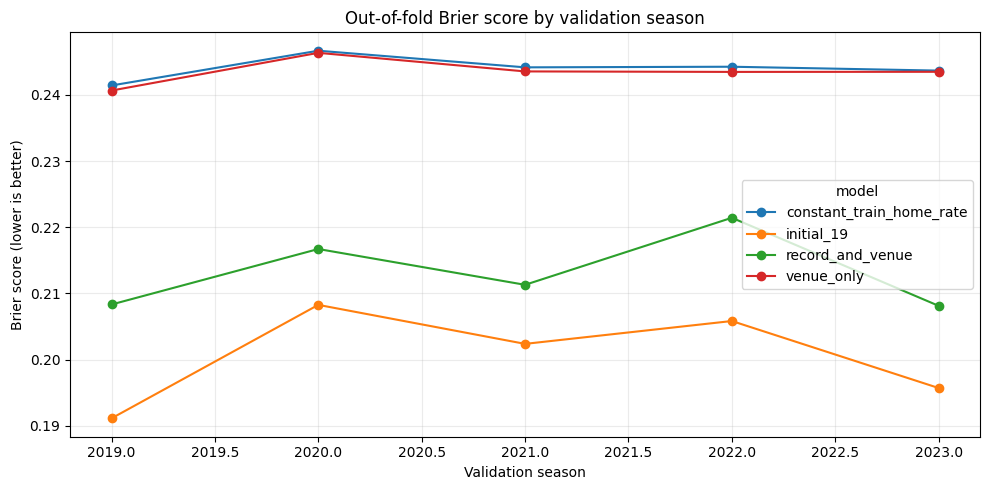

Initial 19-feature model calibration by probability bin:


,bin,n_games,avg_predicted_probability,actual_home_win_rate
0,"(-0.001, 0.1]",31,0.068,0.032
1,"(0.1, 0.2]",134,0.154,0.164
2,"(0.2, 0.3]",268,0.256,0.246
3,"(0.3, 0.4]",333,0.355,0.348
4,"(0.4, 0.5]",450,0.452,0.438
5,"(0.5, 0.6]",537,0.551,0.534
6,"(0.6, 0.7]",785,0.652,0.684
7,"(0.7, 0.8]",520,0.749,0.738
8,"(0.8, 0.9]",412,0.845,0.823
9,"(0.9, 1.0]",176,0.929,0.909


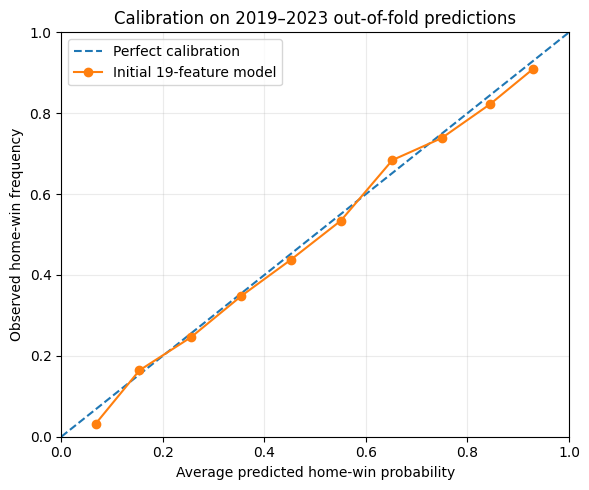

In [ ]:
# Brier score by validation season; lower is better.
pivot = fold_scores.pivot(index='validation_season', columns='model', values='brier')
ax = pivot.plot(marker='o', figsize=(10, 5))
ax.set_title('Out-of-fold Brier score by validation season')
ax.set_xlabel('Validation season')
ax.set_ylabel('Brier score (lower is better)')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Simple reliability table and plot for the full 19-feature model.
cal = oof_predictions.loc[oof_predictions['model'].eq('initial_19')].copy()
cal['bin'] = pd.cut(cal['predicted_p_home_win'],
                    bins=np.linspace(0, 1, 11), include_lowest=True)
reliability = cal.groupby('bin', observed=False).agg(
    n_games=('actual_home_win', 'size'),
    avg_predicted_probability=('predicted_p_home_win', 'mean'),
    actual_home_win_rate=('actual_home_win', 'mean'),
).reset_index()
print('Initial 19-feature model calibration by probability bin:')
display(reliability.round(3))

used = reliability.loc[reliability.n_games > 0]
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], '--', label='Perfect calibration')
ax.plot(used['avg_predicted_probability'], used['actual_home_win_rate'],
        marker='o', label='Initial 19-feature model')
ax.set(xlim=(0, 1), ylim=(0, 1),
       xlabel='Average predicted home-win probability',
       ylabel='Observed home-win frequency',
       title='Calibration on 2019–2023 out-of-fold predictions')
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Save validation artifacts to Drive



In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
files = {
    'fold_scores': OUTPUT_DIR / 'baseline_fold_scores.csv',
    'mean_fold_scores': OUTPUT_DIR / 'baseline_mean_fold_scores.csv',
    'pooled_scores': OUTPUT_DIR / 'baseline_pooled_scores.csv',
    'validation_predictions': OUTPUT_DIR / 'baseline_oof_predictions_2019_2023.csv',
    'calibration': OUTPUT_DIR / 'initial19_calibration_bins.csv',
    'experiment_config': OUTPUT_DIR / 'baseline_experiment_config.json',
}
fold_scores.to_csv(files['fold_scores'], index=False)
mean_fold_scores.to_csv(files['mean_fold_scores'], index=False)
pooled_scores.to_csv(files['pooled_scores'], index=False)
oof_predictions.to_csv(files['validation_predictions'], index=False)
reliability.to_csv(files['calibration'], index=False)
config = {
    'objective': 'pregame home-win probability on verified FBS-vs-FBS games',
    'target': 'home_win',
    'validation_folds': folds,
    'reserved_test_seasons': sorted(TEST_SEASONS),
    'feature_groups': FEATURE_SETS,
    'model': 'LogisticRegression(solver=lbfgs, C=1.0, max_iter=2000)',
    'preprocessing': 'median imputation + missing indicators + standard scaling, fit on each training fold only',
    'model_selection_metric': 'Brier score (log loss also inspected)',
    'notes': 'Historical FBS–FCS game results may contribute to initial rolling team history; opponent adjustment comes later.'
}
files['experiment_config'].write_text(json.dumps(config, indent=2), encoding='utf-8')
print('Saved validation artifacts:')
for label, path in files.items():
    print(f' - {label}: {path}')
print('Final test seasons remain reserved and were not evaluated.')

Saved validation artifacts:
 - fold_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/baseline_fold_scores.csv
 - mean_fold_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/baseline_mean_fold_scores.csv
 - pooled_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/baseline_pooled_scores.csv
 - validation_predictions: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/baseline_oof_predictions_2019_2023.csv
 - calibration: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/initial19_calibration_bins.csv
 - experiment_config: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/baseline_experiment_config.json
Final test seasons remain reserved and were not evaluated.
